# P2.05 — Supply against demand: did housing keep pace with households?

**Questions:** RQ2.1 and RQ2.2 (how much was built, licensed and completed), RQ2.3 (did supply keep pace with
population and household growth), RQ2.4 (primary, secondary and vacant stock), RQ3.4 (households against
population), RQ4.5 (which regions show the largest imbalance).

**Two periods, because the data differ** (`src/pthousing/analysis/supply.py`):
* **2011 to 2021, observed:** the censuses count conventional dwellings and private households, so the balance
  (dwellings added minus households added, per 1,000 households at the start) is a count, not an estimate;
* **2021 to 2023, implied:** no census, so new households are *implied* by population growth (annual estimates)
  divided by 2021 persons per household, and supply is the new family dwellings completed in 2022 and 2023. This
  is a proxy for the pressure: it ignores demolitions, conversions and renovation, and population estimates are
  revised.

Same sign in both: negative means construction fell short of the new households. Everything is descriptive or an
adjusted association.

In [1]:
import numpy as np
import pandas as pd

from pthousing.analysis import supply
from pthousing.data import build_panel, typology
from pthousing.viz import charts, maps, style

style.apply_style()
panel = build_panel.read("panel_municipality_year")
stock = supply.read_stock()
ty = typology.read().set_index("muni_code")
area = supply.area_of(panel)
bal = supply.balance(panel, stock)
print(bal.shape, "municipalities:", bal.index.nunique())

(308, 19) municipalities: 308


## Step 1 — How much was built? (RQ2.1, RQ2.2)
New family dwellings licensed and completed per year, summed over the 308 municipalities.

1995-2025 completed: 1,533,362; licensed: 1,632,300
peak completions 2002: 125,708; trough 2015: 7,148; 2025: 27,301
1995-2004: completed 932,151 (93,215 a year)
2005-2014: completed 422,093 (42,209 a year)
2015-2025: completed 179,118 (16,283 a year)


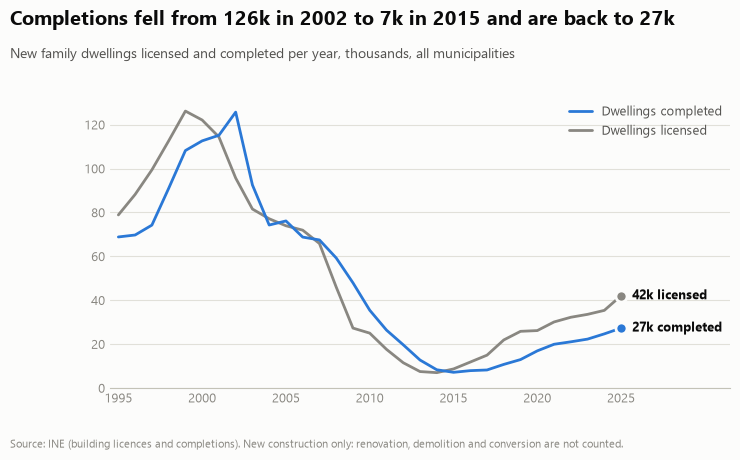

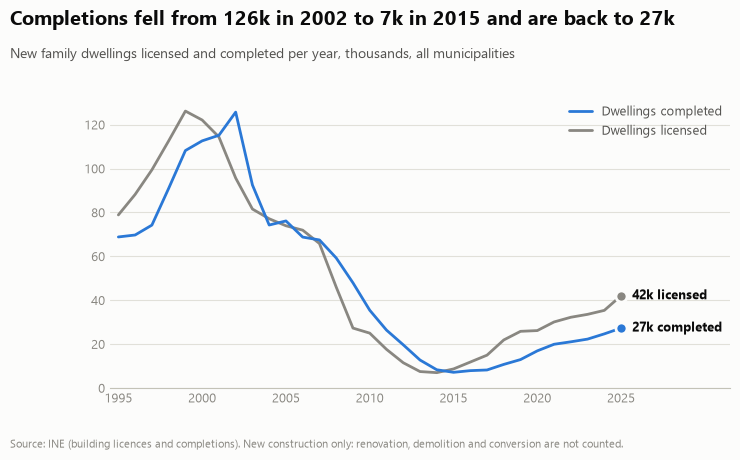

In [2]:
flows = supply.national_flows(panel)
style.save_table(flows.reset_index(), "p2", "construction_flows")
done = flows["completed_n"]
print(f"1995-2025 completed: {done.sum():,.0f}; licensed: {flows['licensed_n'].sum():,.0f}")
print(
    f"peak completions {done.idxmax()}: {done.max():,.0f}; trough {done.loc[2005:].idxmin()}: "
    f"{done.loc[2005:].min():,.0f}; 2025: {done.iloc[-1]:,.0f}"
)
for a, b in ((1995, 2004), (2005, 2014), (2015, 2025)):
    print(f"{a}-{b}: completed {done.loc[a:b].sum():,.0f} ({done.loc[a:b].mean():,.0f} a year)")
fig = charts.construction_flows(flows)
style.save_fig(fig, "p2", "construction_flows")
fig

## Step 2 — Dwellings against households and population, 2011 to 2021 (RQ2.3, RQ3.4)

In [3]:
nat = supply.aggregate(bal, pd.Series("Portugal", index=bal.index)).loc["Portugal"]
print(
    f"dwellings {nat['dwellings_2011_n']:,.0f} -> {nat['dwellings_2021_n']:,.0f} ({nat['dwellings_change_pct']:+.1f}%)\n"
    f"households {nat['households_2011_n']:,.0f} -> {nat['households_2021_n']:,.0f} ({nat['households_change_pct']:+.1f}%)\n"
    f"population (estimates) {nat['population_2011_n']:,.0f} -> {nat['population_2021_n']:,.0f} ({nat['population_change_2011_2021_pct']:+.1f}%)\n"
    f"persons per household {nat['persons_per_household_2011']:.2f} -> {nat['persons_per_household_2021']:.2f}\n"
    f"national gap {nat['supply_gap_2011_2021_per_1000']:+.1f} per 1,000 households; completions 2012-2021 "
    f"{nat['completions_2012_2021_n']:,.0f} against +{nat['dwellings_2021_n'] - nat['dwellings_2011_n']:,.0f} dwellings"
)

dwellings 5,859,540 -> 5,970,677 (+1.9%)
households 4,043,726 -> 4,149,096 (+2.6%)
population (estimates) 10,558,950 -> 10,599,117 (+0.4%)
persons per household 2.61 -> 2.55
national gap +1.4 per 1,000 households; completions 2012-2021 124,572 against +111,137 dwellings


The national balance hides geography: the stock grew roughly with households *in total*, but households grew in
few places and fell in many. Split municipalities by what happened to their households:

In [4]:
bal["households_trend"] = np.where(
    bal["households_change_pct"] < 0, "households fell", "households grew"
)
trend = supply.aggregate(bal, bal["households_trend"])
trend["added_dwellings_n"] = trend["dwellings_2021_n"] - trend["dwellings_2011_n"]
trend["added_households_n"] = trend["households_2021_n"] - trend["households_2011_n"]
cols = [
    "municipalities_n",
    "added_dwellings_n",
    "added_households_n",
    "supply_gap_2011_2021_per_1000",
]
print(trend[cols].round(1).to_string())
style.save_table(trend[cols].reset_index(), "p2", "housing_balance_by_household_trend")

                  municipalities_n  added_dwellings_n  added_households_n  supply_gap_2011_2021_per_1000
households_trend                                                                                        
households fell                169              11510              -41325                           47.9
households grew                139              99627              146695                          -16.0


WindowsPath('D:/Projects/portugal-housing-crisis/reports/tables/p2/housing_balance_by_household_trend.csv')

## Step 3 — What kind of stock? Usual, secondary, vacant (RQ2.4)

In [5]:
comp_nat = supply.composition(stock)
style.save_table(comp_nat, "p2", "stock_composition_national")
print(comp_nat.round(1).to_string(index=False))
comp_class = pd.concat(
    [
        supply.composition(stock, ty[dim]).assign(dimension=dim)
        for dim in ("coast_class", "density_class")
    ]
)
style.save_table(comp_class, "p2", "stock_composition_by_class")
print(comp_class[comp_class["census_year"] == 2021].round(1).to_string(index=False))

   group  census_year  dwellings_n  usual_pct  secondary_pct  vacant_pct
Portugal         2011      5859540       68.1           19.3        12.5
Portugal         2021      5970677       69.4           18.5        12.1
       group  census_year  dwellings_n  usual_pct  secondary_pct  vacant_pct     dimension
       coast         2021      2574844       70.8           18.2        11.0   coast_class
     estuary         2021       556235       76.6            9.6        13.8   coast_class
      inland         2021      2839598       66.6           20.5        12.8   coast_class
intermediate         2021      1979023       67.8           20.1        12.2 density_class
       rural         2021      1589979       54.3           31.0        14.6 density_class
       urban         2021      2401675       80.7            8.9        10.4 density_class


## Step 4 — Where is the imbalance? By district (RQ4.5)

In [6]:
by_area = supply.aggregate(bal, area)
cols = [
    "municipalities_n",
    "households_change_pct",
    "dwellings_change_pct",
    "supply_gap_2011_2021_per_1000",
    "population_change_2021_2023_pct",
    "completions_2022_2023_per_1000",
    "implied_gap_2021_2023_per_1000",
]
style.save_table(by_area[cols].round(2).reset_index(names="area"), "p2", "housing_balance_by_area")
print(by_area[cols].sort_values("supply_gap_2011_2021_per_1000").round(1).to_string())

                  municipalities_n  households_change_pct  dwellings_change_pct  supply_gap_2011_2021_per_1000  population_change_2021_2023_pct  completions_2022_2023_per_1000  implied_gap_2021_2023_per_1000
district                                                                                                                                                                                                       
Setúbal                         13                    6.0                   2.2                          -30.2                              8.3                             7.8                           -72.8
Lisboa                          16                    3.1                   0.5                          -23.9                              8.0                             5.5                           -73.4
Porto                           18                    4.5                   1.7                          -23.4                              4.0                         

{'census': np.float64(1.4261599326957366), 'after': np.float64(-46.4457897852139)} new households implied 236,035, completions 43,327


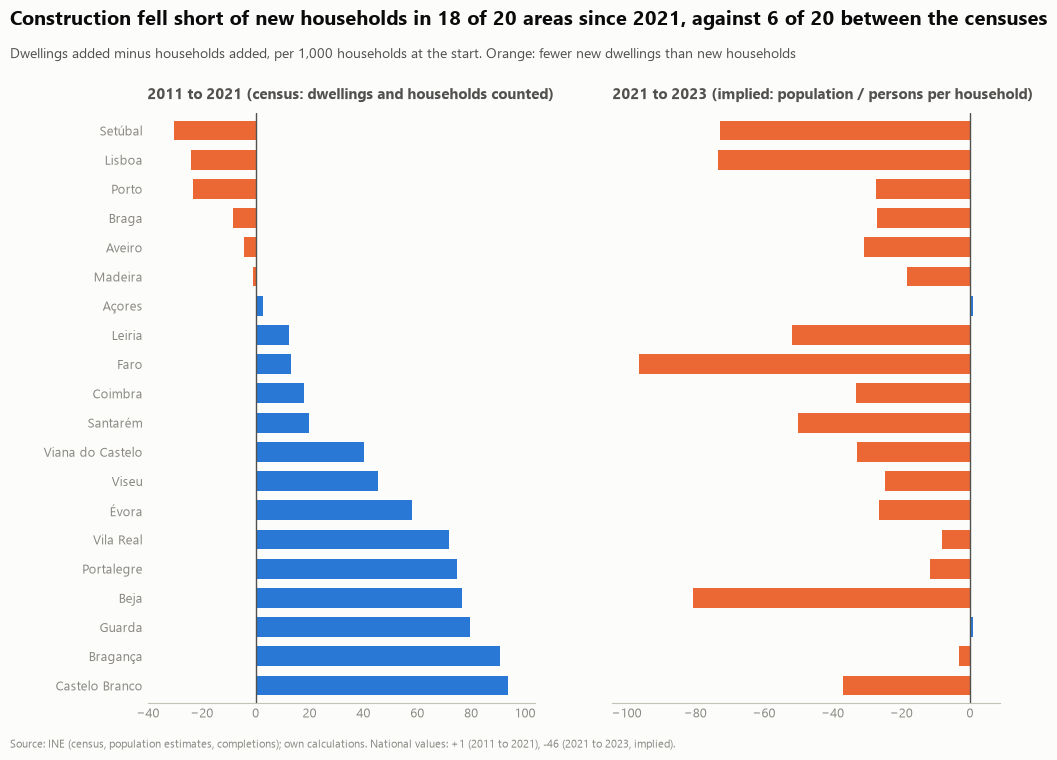

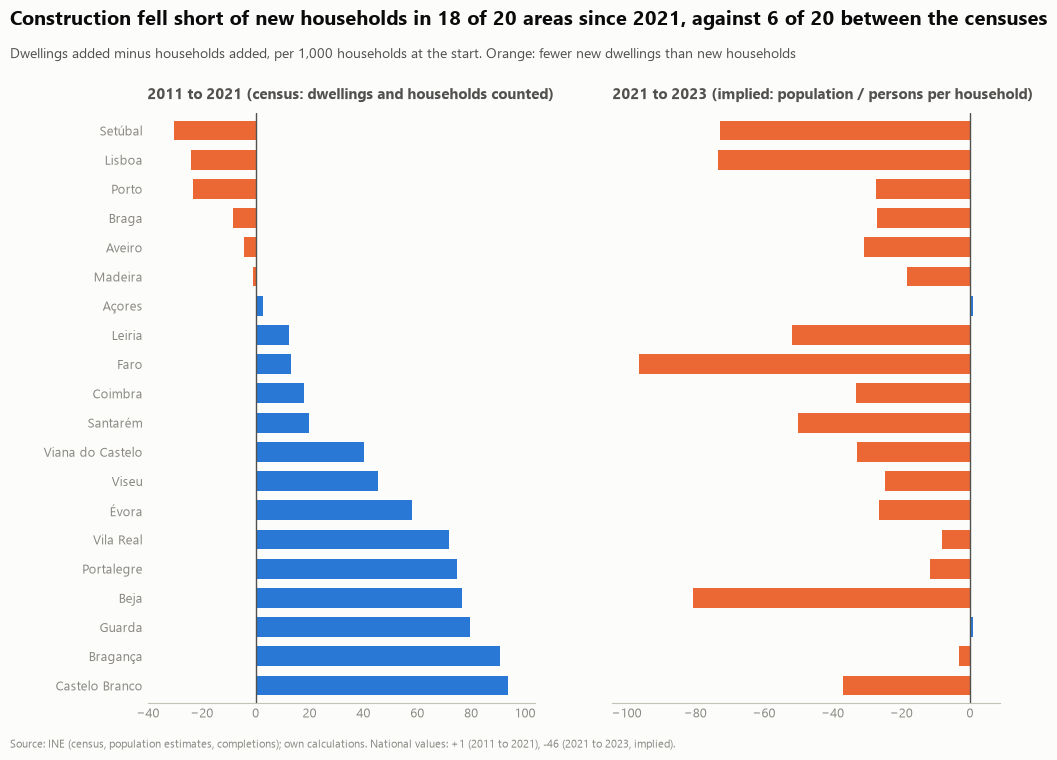

In [7]:
headline = {
    "census": nat["supply_gap_2011_2021_per_1000"],
    "after": nat["implied_gap_2021_2023_per_1000"],
}
print(
    headline,
    f"new households implied {nat['implied_new_households_2021_2023_n']:,.0f}, completions {nat['completions_2022_2023_n']:,.0f}",
)
fig = charts.housing_balance_by_area(
    by_area["supply_gap_2011_2021_per_1000"], by_area["implied_gap_2021_2023_per_1000"], headline
)
style.save_fig(fig, "p2", "housing_balance_by_area")
fig

**Maps** (red = shortfall: fewer new dwellings than new households; blue = surplus). Municipalities are the
unit; the first map is observed, the second implied.

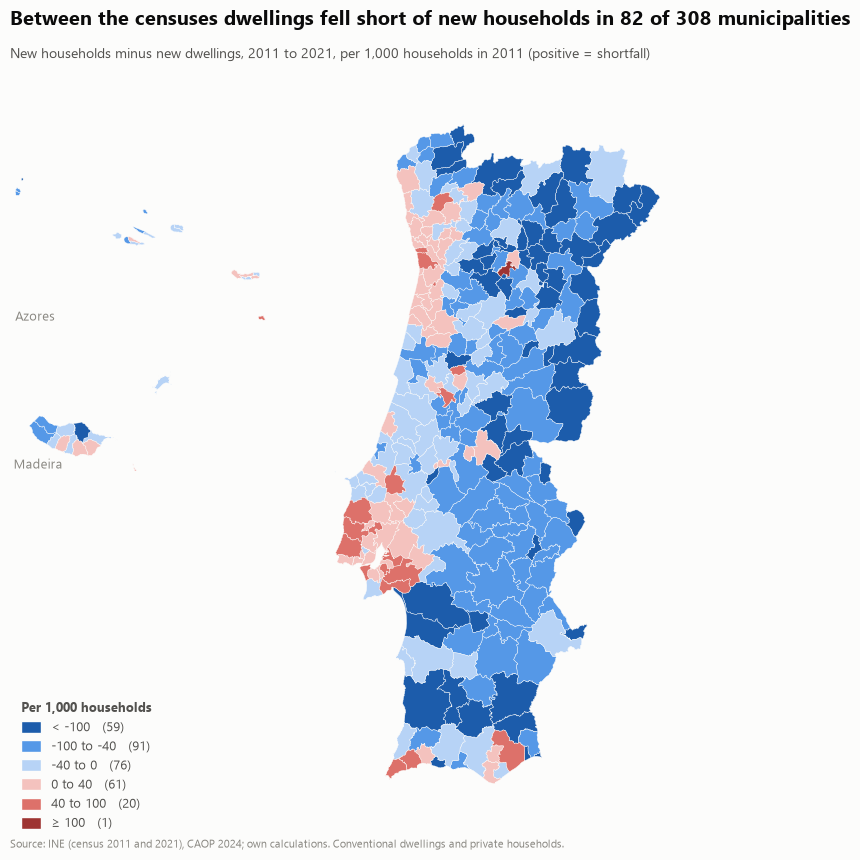

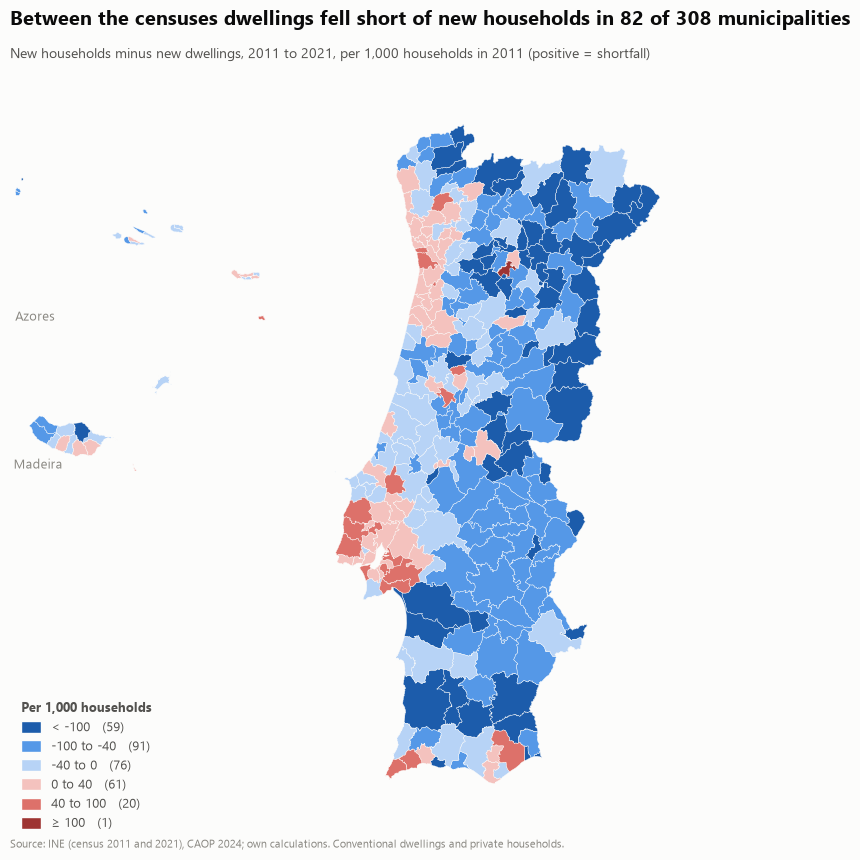

In [8]:
geometry = maps.municipality_geometry()
short1 = -bal["supply_gap_2011_2021_per_1000"]
n1 = int((short1 > 0).sum())
fig = maps.choropleth(
    short1, geometry, [-100, -40, 0, 40, 100], style.diverging_ramp(3),
    f"Between the censuses dwellings fell short of new households in {n1} of {len(short1)} municipalities",
    "New households minus new dwellings, 2011 to 2021, per 1,000 households in 2011 (positive = shortfall)",
    "Source: INE (census 2011 and 2021), CAOP 2024; own calculations. Conventional dwellings and private households.",
    "Per 1,000 households",
)  # fmt: skip
style.save_fig(fig, "p2", "housing_shortfall_map_2011_2021")
fig

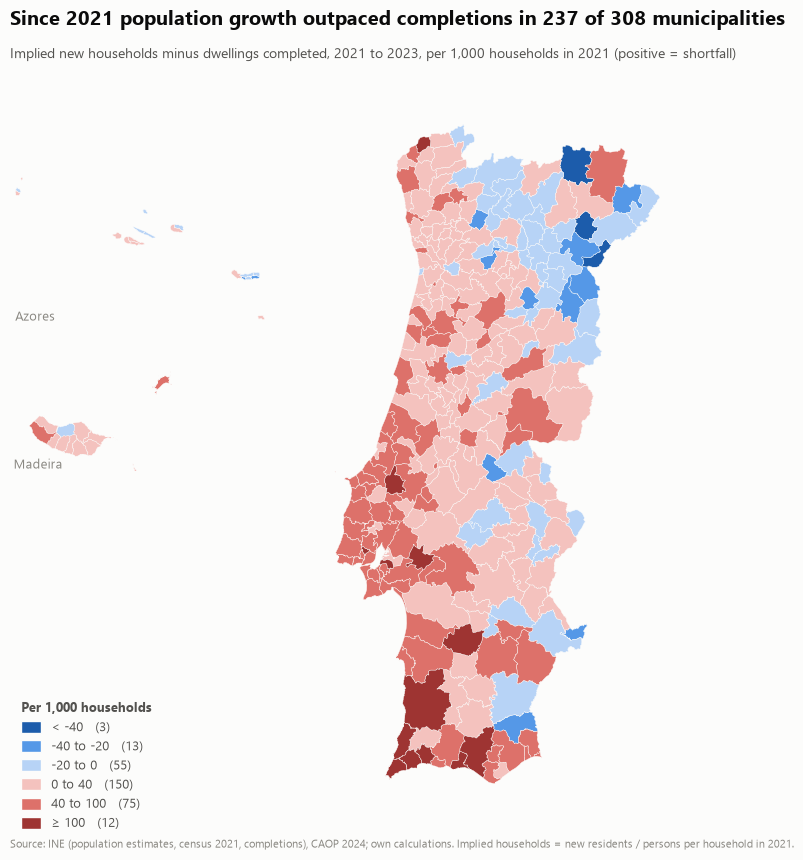

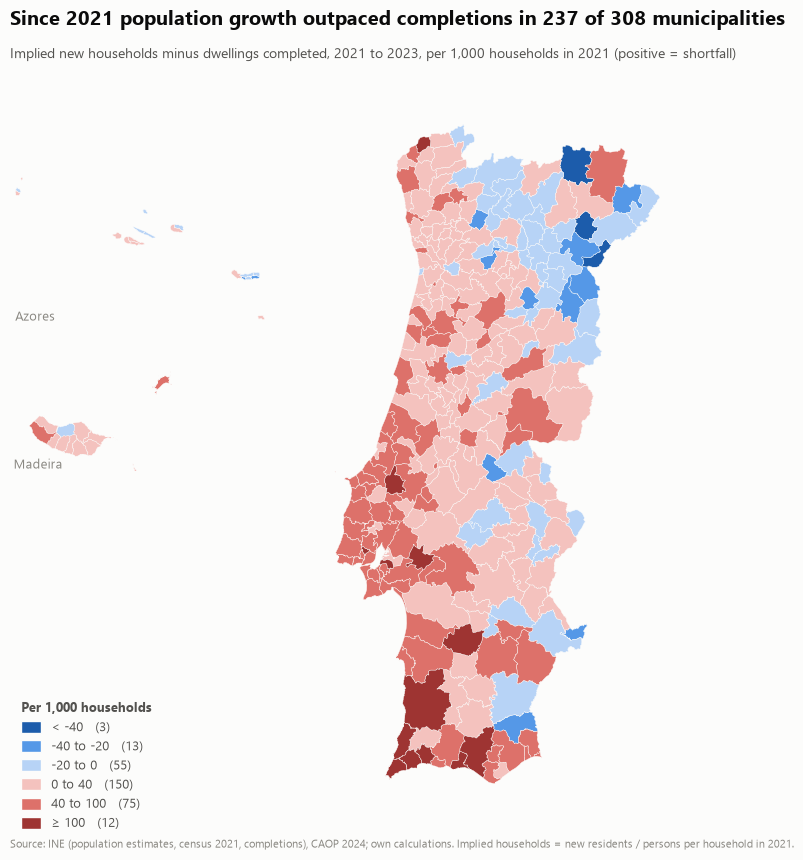

In [9]:
short2 = -bal["implied_gap_2021_2023_per_1000"]
n2 = int((short2 > 0).sum())
fig = maps.choropleth(
    short2, geometry, [-40, -20, 0, 40, 100], style.diverging_ramp(3),
    f"Since 2021 population growth outpaced completions in {n2} of {len(short2)} municipalities",
    "Implied new households minus dwellings completed, 2021 to 2023, per 1,000 households in 2021 (positive = shortfall)",
    "Source: INE (population estimates, census 2021, completions), CAOP 2024; own calculations. Implied households = new residents / persons per household in 2021.",
    "Per 1,000 households",
)  # fmt: skip
style.save_fig(fig, "p2", "housing_shortfall_map_2021_2023")
fig

## Step 5 — Is the imbalance related to where affordability worsened?
Cross-section of the 271 mainland municipalities with a price-to-income in 2016 and 2024. Outcome: log change of
price-to-income. Drivers, one set per period: the census changes in dwellings and households (2011 to 2021,
% each) and since the census the population growth and the completions of 2022 and 2023 (per 1,000 dwellings).
Each model compares municipalities of the same district; the last adds coast and density class. Robust (HC3)
errors. These are adjusted associations: construction follows prices, households move to where prices are
rising, and the 2016 to 2024 outcome overlaps both periods.

In [10]:
d = bal.join(supply.pti_change(panel, 2016, 2024)).join(
    ty[["coast_class", "density_class", "territory"]]
)
d["district"] = area
d = d[d["territory"] == "continente"]
d = d.rename(
    columns={
        "supply_gap_2011_2021_per_1000": "gap_census",
        "implied_gap_2021_2023_per_1000": "gap_after",
        "population_change_2021_2023_pct": "pop_change_after_pct",
        "completions_2022_2023_per_1000": "completions_after",
    }
)
print(f"{d['dlog_pti'].notna().sum()} mainland municipalities with a price-to-income change")
print(
    d[
        [
            "gap_census",
            "households_change_pct",
            "dwellings_change_pct",
            "pop_change_after_pct",
            "completions_after",
            "gap_after",
        ]
    ]
    .corr()
    .round(2)
    .to_string()
)
MODELS = {
    "Census gap": (["gap_census"], None),
    "Census households and dwellings": (["households_change_pct", "dwellings_change_pct"], None),
    "Since 2021: population and completions": (["pop_change_after_pct", "completions_after"], None),
    "All four": (
        [
            "households_change_pct",
            "dwellings_change_pct",
            "pop_change_after_pct",
            "completions_after",
        ],
        None,
    ),
    "All four + coast and density": (
        [
            "households_change_pct",
            "dwellings_change_pct",
            "pop_change_after_pct",
            "completions_after",
        ],
        ["coast_class", "density_class"],
    ),
}
assoc = pd.concat(
    [
        supply.associations(
            d, "dlog_pti", xs, fixed_effects="district", categorical=cats, label=name
        )
        for name, (xs, cats) in MODELS.items()
    ],
    ignore_index=True,
)
style.save_table(assoc, "p2", "supply_demand_associations")
print(
    assoc[["spec", "term", "coef", "se", "p", "coef_per_sd", "n_obs", "r2"]]
    .round(3)
    .to_string(index=False)
)

271 mainland municipalities with a price-to-income change
                       gap_census  households_change_pct  dwellings_change_pct  pop_change_after_pct  completions_after  gap_after
gap_census                   1.00                  -0.74                  0.23                 -0.51              -0.44       0.48
households_change_pct       -0.74                   1.00                  0.47                  0.62               0.64      -0.55
dwellings_change_pct         0.23                   0.47                  1.00                  0.16               0.38      -0.10
pop_change_after_pct        -0.51                   0.62                  0.16                  1.00               0.34      -0.99
completions_after           -0.44                   0.64                  0.38                  0.34               1.00      -0.19
gap_after                    0.48                  -0.55                 -0.10                 -0.99              -0.19       1.00
                         

**Sensitivity:** the "All four" model without the three metropolitan districts (Lisboa, Setúbal, Porto), and
with the census gap and the implied gap (which is almost minus the population growth) instead.

In [11]:
four = MODELS["All four"][0]
rows = [
    supply.associations(
        d[~d["district"].isin(["Lisboa", "Setúbal", "Porto"])],
        "dlog_pti", four, fixed_effects="district", label="All four, without Lisboa, Setúbal, Porto",
    ),
    supply.associations(
        d, "dlog_pti", ["gap_census", "gap_after"], fixed_effects="district", label="Census gap and implied gap"
    ),
    supply.associations(
        d, "dlog_pti", ["gap_census", "gap_after"], fixed_effects="district",
        categorical=["coast_class", "density_class"], label="Census gap and implied gap + coast and density",
    ),
]  # fmt: skip
sens = pd.concat(rows, ignore_index=True)
style.save_table(sens, "p2", "supply_demand_sensitivity")
print(
    sens[["spec", "term", "coef", "se", "p", "coef_per_sd", "n_obs"]]
    .round(3)
    .to_string(index=False)
)

                                          spec                  term   coef    se     p  coef_per_sd  n_obs
      All four, without Lisboa, Setúbal, Porto households_change_pct  0.006 0.006 0.281        0.036    224
      All four, without Lisboa, Setúbal, Porto  dwellings_change_pct -0.005 0.007 0.488       -0.014    224
      All four, without Lisboa, Setúbal, Porto  pop_change_after_pct  0.009 0.006 0.139        0.034    224
      All four, without Lisboa, Setúbal, Porto     completions_after  0.011 0.004 0.008        0.048    224
                    Census gap and implied gap            gap_census -0.001 0.000 0.013       -0.052    271
                    Census gap and implied gap             gap_after -0.001 0.000 0.009       -0.047    271
Census gap and implied gap + coast and density            gap_census -0.000 0.000 0.156       -0.026    271
Census gap and implied gap + coast and density             gap_after -0.001 0.000 0.181       -0.023    271


## Findings

1. **Construction collapsed and has recovered only partly (RQ2.1, RQ2.2).** 1.53 million new family dwellings
   were completed in 1995 to 2025. Completions peaked at 126,000 in 2002, fell to 7,100 in 2015 and were 27,300 in
   2025; the average was 93,000 a year in 1995 to 2004, 42,000 in 2005 to 2014 and 16,000 in 2015 to 2025. Licences
   (42,000 in 2025) run ahead of completions, as they should while construction is recovering.
2. **Between the censuses supply kept pace nationally, not locally (RQ2.3, RQ3.4).** Dwellings grew 1.9% (+111,000),
   households 2.6% (+105,000) and the population 0.4%; persons per household fell from 2.61 to 2.55. The national
   balance is +1.4 per 1,000 households, but it is the sum of two groups: in 169 municipalities households *fell*
   (−41,000) and 11,500 dwellings were still added (+48 per 1,000), in the 139 where households grew (+147,000)
   dwellings grew less (+99,600, −16 per 1,000).
3. **Where the shortfall was (RQ4.5).** 2011 to 2021: Setúbal (−30 per 1,000), Lisboa (−24), Porto (−23), Braga
   and Aveiro fell short and Madeira was level; the interior (Castelo Branco +94, Bragança +91, Guarda +79, Beja
   +77) added dwellings while losing households. Since 2021 the pressure is everywhere and largest in Faro (−96),
   Beja (−80), Lisboa and Setúbal (−73) and Leiria (−52): 236,000 implied new households against 43,300 dwellings
   completed in 2022 and 2023 (−46 per 1,000), a shortfall in 18 of 20 areas and 237 of 308 municipalities.
   These are implied from population estimates, so the size is uncertain; the geography and the order of
   magnitude are the findings.
4. **The stock is not mostly vacant or second homes (RQ2.4).** In 2021, 69.4% of dwellings were usual residence
   (68.1% in 2011), 18.5% secondary (19.3%) and 12.1% vacant (12.5%; 723,000 dwellings). Urban municipalities are
   81% usual residence and 10% vacant; rural ones 54% usual, 31% secondary, 15% vacant. The vacant stock is largest
   where there is no demand; how much could return to use (RQ2.5) needs location and condition data not used here.
5. **Relation to affordability: weak and not robust (adjusted associations).** Within a district, municipalities
   where dwellings grew more than households in 2011 to 2021 had a smaller rise in price-to-income 2016 to 2024
   (census gap: −6.8% per standard deviation, p = 0.001; households +9.6%, dwellings −3.8% per sd), and those with
   more population growth since 2021 a larger one (+6.3% per sd). Holding both periods together the signs stay but
   with coast and density class added, they fade (dwellings −2.5%, p = 0.13; population +3.0%, p = 0.12; census
   gap −2.6%, p = 0.16), and without Lisboa, Setúbal and Porto the census terms lose significance. Only
   completions in 2022 and 2023 keep a positive coefficient (+2.9% to +4.8% per sd, p ≤ 0.025): supply follows
   prices, not the reverse.

**Limits.** Census years are 10 years apart and the price outcome starts in 2016, so the periods overlap the
outcome and neighbouring data points are not independent. The implied households of 2021 to 2023 divide new
residents by persons per household in 2021, ignore household-size change and revised estimates, and completions
exclude renovation, conversion and demolition, so the post-2021 gap overstates the shortfall if households form
smaller or immigrants share homes. Dwellings are conventional dwellings of any quality (a vacant ruin counts).
The regressions have 271 municipalities and 18 districts and are not causal.